# 05 — Modelling (Path B · Stages 4–6)

**Issue-tree branch F: can launch metadata pick hits?** The greenlight committee's question is not
"what is the AUC" but **"if we rank next year's candidate releases by a score, how many of the top of
that ranking will sell a million — and is that better than what we already know?"**

### Design decisions, fixed before any model is fitted

| Decision | Choice | Why |
|---|---|---|
| Target | `is_hit` = lifetime units ≥ 1 M (12.5% of rows) | The review's best-fitting predictive task; a binary threshold the committee already uses |
| Unit | one release (game × platform) | the greenlight decision is per SKU |
| Split | **train ≤ 2011 · test 2012–14**; tuning on train ≤ 2008 vs validate 2009–11 | temporal — a random split would let 2013's platform mix inform 2012's predictions |
| Title grouping | test rows whose title appears in train are **removed** | the same game on another platform would leak its own outcome |
| Censored years | 2015–16 **excluded** from evaluation | their lifetime sales are incomplete (`03` §3.1); a 2016 "non-hit" may simply not have finished selling |
| Features | **only what is known at greenlight**: platform, genre, manufacturer, platform type and age, year, first-party flag, number of platforms launched the same year, and the publisher's **track record from strictly earlier years** | |
| Excluded as leakage | regional sales, `Rank`, `Global_Sales`, lifetime platform count (counts later ports), any title aggregate | the review's §6 rule 1, plus two leaks it did not list |
| Metrics | PR-AUC (imbalanced target), **precision in the top 10% of the ranking**, ROC-AUC, Brier; cluster-bootstrap CIs by title | precision@10% is the number the committee would actually experience |
| Baselines | prevalence; first-party flag alone; publisher prior hit rate alone | a model must beat the committee's existing heuristics, not just chance |

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
N_BOOT = 2000
pd.set_option("display.width", 200)

ROOT = Path.cwd()
while not (ROOT / "archive" / "vgsales.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ARCHIVE = ROOT / "archive"
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS, MODELS = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "models"
for p in (RAW, PROC, REPORTS, FIGS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

KF_PATH = REPORTS / "_key_figures.json"


def _plain(v):
    if hasattr(v, "item"):
        return v.item()
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    return v


def kf_update(**kw):
    """Append to reports/_key_figures.json — the only place the report reads numbers from."""
    kf = json.loads(KF_PATH.read_text()) if KF_PATH.exists() else {}
    kf.update({k: _plain(v) for k, v in kw.items()})
    KF_PATH.write_text(json.dumps(kf, indent=1, sort_keys=True))
    print(f"  _key_figures.json <- {', '.join(kw)}  ({len(kf)} figures total)")

# ---------------------------------------------------------------------------------------------
# DESIGN.md palette, defined inline (no local module imports — a fresh clone must run as-is).
#
# Validated with the dataviz skill's checker rather than eyeballed:
#   node scripts/validate_palette.js "#2251FF,#008A7E,#C1841C" --mode light
#     PASS lightness | PASS chroma floor | PASS CVD separation (worst adjacent dE 12.5 protan)
#     PASS normal-vision separation (21.1) | PASS contrast vs surface
# DESIGN.md's Teal #00857C FAILS the chroma floor (C = 0.097 < 0.10, reads as grey), so it is
# nudged to #008A7E — same hue, +0.005 chroma. Cyan and Slate are not used as identities.
# Grey is context ink only; Navy is text ink only; neither is ever a series colour.
# ---------------------------------------------------------------------------------------------
NAVY, BLUE, TEAL, AMBER = "#051C2C", "#2251FF", "#008A7E", "#C1841C"
SLATE, GREY, GRID, LIGHT = "#7F93A6", "#9FADB8", "#E9ECEF", "#D5DCE2"

# Semantic mapping, fixed once and used in every notebook:
C_FOCUS = BLUE        # the emphasis story: hits, first-party, Japan, the model
C_SECOND = TEAL       # the second series: Europe, the tail, third-party comparison
C_REF = AMBER         # reference lines, censored years, baselines, Other region
C_CONTEXT = GREY      # non-highlighted context (incl. North America in regional mixes)
REGION_COLORS = {"NA": GREY, "EU": TEAL, "JP": BLUE, "Other": AMBER}


def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
        "axes.facecolor": "white", "savefig.facecolor": "white",
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9, "text.color": NAVY,
        "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "lines.linewidth": 2.0, "lines.markersize": 8,
    })


apply_style()
PCT = PercentFormatter(1.0)
SOURCE = "vgsales.csv (vgchartz.com scrape, snapshot c. late 2016)"


def finish(fig, note=""):
    """Every exhibit carries its source line — STRUCTURE.md Step 7.3."""
    fig.text(0.005, -0.015, f"Source: {SOURCE}" + (f" · {note}" if note else ""),
             fontsize=7, color=SLATE, ha="left", va="top")


def suptitle(fig, text, y=1.04):
    fig.suptitle(text, x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=y)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")


df = pd.read_parquet(PROC / "vg_rows.parquet")
d = df[df.Year.notna()].copy()
d["Year"] = d.Year.astype(int)
for c in ["Platform", "Genre"]:
    d[c] = d[c].astype(str)
print(f"{len(d):,} rows with a release year")

16,435 rows with a release year


## 4 — Feature engineering (launch-time only)

**Publisher track record** is the one feature family that uses outcomes, so it is built with an
explicit time fence: for a release in year *t*, only the publisher's releases from years **< t**
contribute. Same-year releases are excluded too (a committee greenlighting a 2012 title does not know
how the publisher's other 2012 titles will sell). The hit rate is shrunk toward the prior-years market
rate with k = 10 pseudo-releases, so a publisher with two prior releases is not scored as 0% or 50%.

In [2]:
# simultaneous multi-platform launch: platforms this title launched on IN THE SAME YEAR (known at greenlight)
d["n_platforms_same_year"] = d.groupby(["Name", "Year"]).Platform.transform("nunique")

# publisher track record, strictly prior years
py = (d.groupby(["Publisher", "Year"])
        .agg(n=("is_hit", "size"), h=("is_hit", "sum"), ls=("log_sales", "sum"))
        .reset_index().sort_values(["Publisher", "Year"]))
for c in ["n", "h", "ls"]:
    py[f"prior_{c}"] = py.groupby("Publisher")[c].cumsum() - py[c]
py["first_year"] = py.groupby("Publisher").Year.transform("min")
mkt = d.groupby("Year").agg(n=("is_hit", "size"), h=("is_hit", "sum")).sort_index()
mkt["prior_rate"] = ((mkt.h.cumsum() - mkt.h) / (mkt.n.cumsum() - mkt.n)).fillna(d.is_hit.mean())
py = py.merge(mkt[["prior_rate"]], left_on="Year", right_index=True)
K = 10
py["pub_prior_hit_rate"] = (py.prior_h + K * py.prior_rate) / (py.prior_n + K)
py["pub_prior_releases"] = np.log1p(py.prior_n)
py["pub_prior_mean_log_sales"] = np.where(py.prior_n > 0, py.prior_ls / py.prior_n.clip(lower=1), np.nan)
py["pub_years_active"] = py.Year - py.first_year
d = d.merge(py[["Publisher", "Year", "pub_prior_hit_rate", "pub_prior_releases",
                "pub_prior_mean_log_sales", "pub_years_active"]], on=["Publisher", "Year"], how="left")
d["publisher_unknown"] = (d.Publisher == "Unknown").astype(int)

# leakage guard: the prior features of a publisher's FIRST year must carry no information about it
first = d[d.pub_years_active == 0]
assert (first.pub_prior_releases == 0).all() and first.pub_prior_mean_log_sales.isna().all()
print("publisher-history time fence verified: first-year releases see zero prior releases")

CAT = ["Platform", "Genre", "manufacturer", "platform_type"]
NUM_TIMING = ["Year", "years_since_launch", "generation"]
NUM_SLATE = ["first_party", "n_platforms_same_year", "publisher_unknown"]
NUM_PUB = ["pub_prior_hit_rate", "pub_prior_releases", "pub_prior_mean_log_sales", "pub_years_active"]
FAMILIES = {"platform & genre": CAT, "timing": NUM_TIMING, "first-party & slate": NUM_SLATE,
            "publisher track record": NUM_PUB}
FEATURES = CAT + NUM_TIMING + NUM_SLATE + NUM_PUB
LEAKY = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales", "Rank", "n_platforms_title",
         "is_multiplatform", "log_sales"]
assert not set(FEATURES) & set(LEAKY)
for c in ["years_since_launch", "generation"]:
    d[c] = d[c].astype(float)
print(f"{len(FEATURES)} features in {len(FAMILIES)} families; {len(LEAKY)} leaky columns excluded")

publisher-history time fence verified: first-year releases see zero prior releases
14 features in 4 families; 9 leaky columns excluded


### Splits

In [3]:
train = d[d.Year <= 2011]
test = d[d.Year.between(2012, 2014)]
n_test_before = len(test)
test = test[~test.Name.isin(train.Name)]
fit_tr = train[train.Year <= 2008]
fit_va = train[train.Year.between(2009, 2011)]
fit_va = fit_va[~fit_va.Name.isin(fit_tr.Name)]

summary = pd.DataFrame({
    "rows": [len(fit_tr), len(fit_va), len(train), len(test)],
    "hit rate": [fit_tr.is_hit.mean(), fit_va.is_hit.mean(), train.is_hit.mean(), test.is_hit.mean()],
    "third-party hit rate": [s[s.first_party == 0].is_hit.mean() for s in (fit_tr, fit_va, train, test)],
}, index=["tune-train ≤2008", "tune-valid 2009–11", "train ≤2011", "TEST 2012–14"])
print(summary.round(3).to_string())
print(f"\ntest rows removed because their title already appears in train: {n_test_before - len(test)}")
BASE = test.is_hit.mean()

                     rows  hit rate  third-party hit rate
tune-train ≤2008     9817     0.141                 0.114
tune-valid 2009–11   3758     0.092                 0.077
train ≤2011         13680     0.127                 0.103
TEST 2012–14         1698     0.144                 0.117

test rows removed because their title already appears in train: 99


## 5 — Models

Two learned models and three baselines. The logistic regression is the interpretable benchmark the
gradient-boosted model has to beat to justify its opacity. Hyperparameters for the boosted model are
chosen on the 2009–11 validation window only; the test window is touched once.

In [4]:
def make_hgb(**kw):
    return HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=RANDOM_STATE,
                                          early_stopping=False, **kw)


def prep(frame, cats=CAT, ref=None):
    X = frame[[c for c in FEATURES if c in frame.columns]].copy()
    for c in cats:
        cats_ = (ref[c].astype("category").cat.categories if ref is not None else None)
        X[c] = pd.Categorical(X[c], categories=cats_) if cats_ is not None else X[c].astype("category")
    return X


grid = [dict(learning_rate=lr, max_leaf_nodes=ml, l2_regularization=l2, max_iter=it)
        for lr in (0.03, 0.06) for ml in (15, 31) for l2 in (0.0, 1.0) for it in (200, 400)]
Xtr, Xva = prep(fit_tr), prep(fit_va, ref=fit_tr)
scores = []
for g in grid:
    m = make_hgb(**g).fit(Xtr, fit_tr.is_hit)
    scores.append({**g, "val_pr_auc": average_precision_score(fit_va.is_hit, m.predict_proba(Xva)[:, 1])})
scores = pd.DataFrame(scores).sort_values("val_pr_auc", ascending=False)
BEST = scores.iloc[0][["learning_rate", "max_leaf_nodes", "l2_regularization", "max_iter"]].to_dict()
BEST = {k: (int(v) if k in ("max_leaf_nodes", "max_iter") else float(v)) for k, v in BEST.items()}
print(scores.head(5).round(4).to_string(index=False))
print(f"\nchosen on validation: {BEST}")

 learning_rate  max_leaf_nodes  l2_regularization  max_iter  val_pr_auc
          0.06              31                1.0       400      0.3150
          0.06              15                0.0       400      0.3133
          0.03              31                0.0       200      0.3121
          0.06              15                0.0       200      0.3110
          0.03              31                1.0       200      0.3086

chosen on validation: {'learning_rate': 0.06, 'max_leaf_nodes': 31, 'l2_regularization': 1.0, 'max_iter': 400}


In [5]:
X_train, X_test = prep(train), prep(test, ref=train)
y_train, y_test = train.is_hit.to_numpy(), test.is_hit.to_numpy()

hgb = make_hgb(**BEST).fit(X_train, y_train)
p_hgb = hgb.predict_proba(X_test)[:, 1]

lr_pipe = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT),
                       ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
                        NUM_TIMING + NUM_SLATE + NUM_PUB)]),
    LogisticRegression(max_iter=3000, C=1.0))
lr_pipe.fit(train[FEATURES], y_train)
p_lr = lr_pipe.predict_proba(test[FEATURES])[:, 1]

PRED = {
    "Gradient-boosted model": p_hgb,
    "Logistic regression": p_lr,
    "Publisher prior hit rate": test.pub_prior_hit_rate.to_numpy(),
    "First-party flag": test.first_party.to_numpy() + 1e-6 * rng.random(len(test)),   # random tie-break
    "Prevalence (no information)": rng.random(len(test)),
}


def prec_at(y, p, q=0.10):
    k = max(1, int(round(len(p) * q)))
    return y[np.argsort(-p)[:k]].mean()


def metrics(y, p):
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "precision@10%": prec_at(y, p), "recall@10%": y[np.argsort(-p)[:max(1, int(round(len(p) * .1)))]].sum() / y.sum()}


# cluster bootstrap by title: a title's platform rows resample together
titles_te = test.Name.to_numpy()
uniq, inv = np.unique(titles_te, return_inverse=True)
members = [np.where(inv == i)[0] for i in range(len(uniq))]


def boot(p, fn, n=N_BOOT):
    out = []
    for _ in range(n):
        idx = np.concatenate([members[i] for i in rng.integers(0, len(uniq), len(uniq))])
        if y_test[idx].sum() == 0:
            continue
        out.append(fn(y_test[idx], p[idx]))
    return np.percentile(out, [2.5, 97.5])


rows = []
for name, p in PRED.items():
    m = metrics(y_test, p)
    lo, hi = boot(p, average_precision_score)
    plo, phi = boot(p, prec_at)
    rows.append({"model": name, **m, "PR-AUC lo": lo, "PR-AUC hi": hi, "prec@10% lo": plo, "prec@10% hi": phi})
res = pd.DataFrame(rows).set_index("model")
res["lift@10%"] = res["precision@10%"] / BASE
res.loc["Prevalence (no information)", "PR-AUC"] = BASE       # its expected value, not one random draw
print(f"TEST 2012–14 · {len(test):,} releases · base rate {BASE:.3f}\n")
print(res.round(3).to_string())

TEST 2012–14 · 1,698 releases · base rate 0.144

                             PR-AUC  ROC-AUC  precision@10%  recall@10%  PR-AUC lo  PR-AUC hi  prec@10% lo  prec@10% hi  lift@10%
model                                                                                                                            
Gradient-boosted model        0.511    0.842          0.571       0.396      0.435      0.589        0.474        0.665     3.955
Logistic regression           0.481    0.852          0.506       0.351      0.411      0.556        0.420        0.589     3.506
Publisher prior hit rate      0.380    0.799          0.453       0.314      0.316      0.449        0.370        0.541     3.139
First-party flag              0.251    0.602          0.388       0.269      0.202      0.317        0.282        0.482     2.691
Prevalence (no information)   0.144    0.514          0.141       0.098      0.124      0.185        0.088        0.195     0.978


### Exhibit 9 — The top decile of a launch-metadata score hits 57% of the time, four times the base rate; the bottom half hits 3%

  saved reports/figures/ex09_model.png


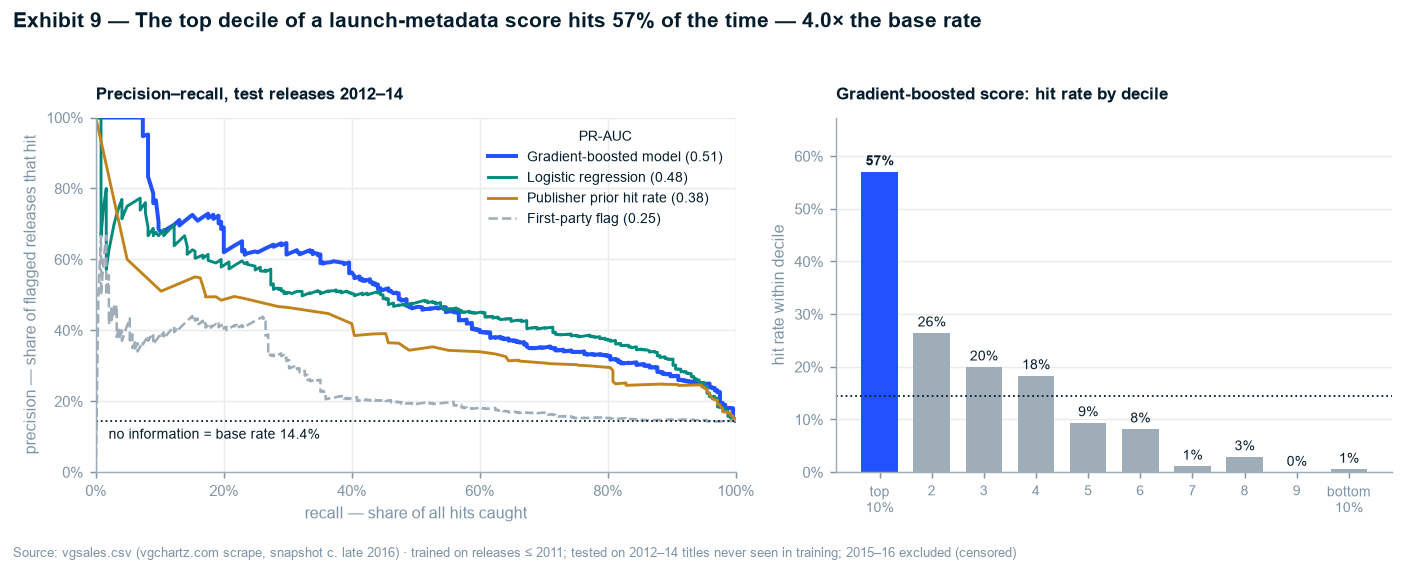

top decile 0.571 · bottom half 0.026 · bottom decile 0.006


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
styles = {"Gradient-boosted model": (BLUE, "-", 2.2), "Logistic regression": (TEAL, "-", 1.6),
          "Publisher prior hit rate": (AMBER, "-", 1.6), "First-party flag": (GREY, "--", 1.4)}
for name, (col, ls, lw) in styles.items():
    pr, rc, _ = precision_recall_curve(y_test, PRED[name])
    ax1.plot(rc, pr, color=col, ls=ls, lw=lw, label=f"{name} ({res.loc[name, 'PR-AUC']:.2f})")
ax1.axhline(BASE, color=NAVY, lw=1, ls=":")
ax1.text(0.02, BASE - 0.05, f"no information = base rate {BASE:.1%}", ha="left", fontsize=8, color=NAVY)
ax1.set_xlabel("recall — share of all hits caught")
ax1.set_ylabel("precision — share of flagged releases that hit")
ax1.xaxis.set_major_formatter(PCT); ax1.yaxis.set_major_formatter(PCT)
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1)
ax1.grid(axis="x")
ax1.legend(loc="upper right", fontsize=7.8, title="PR-AUC", title_fontsize=8)
ax1.set_title("Precision–recall, test releases 2012–14", fontsize=9.5)

dec = pd.DataFrame({"p": p_hgb, "y": y_test})
dec["decile"] = 10 - pd.qcut(dec.p.rank(method="first"), 10, labels=False)
by_dec = dec.groupby("decile").y.mean()
cols = [BLUE if i == 1 else GREY for i in by_dec.index]
ax2.bar(by_dec.index, by_dec.values, color=cols, width=0.7)
ax2.axhline(BASE, color=NAVY, lw=1, ls=":")
for i, v in by_dec.items():
    ax2.text(i, v + 0.012, f"{v:.0%}", ha="center", fontsize=8, color=NAVY, fontweight="bold" if i == 1 else "normal")
ax2.set_xticks(range(1, 11), ["top\n10%"] + [str(i) for i in range(2, 10)] + ["bottom\n10%"], fontsize=8)
ax2.set_ylabel("hit rate within decile")
ax2.yaxis.set_major_formatter(PCT)
ax2.set_ylim(0, max(by_dec) * 1.18)
ax2.set_title("Gradient-boosted score: hit rate by decile", fontsize=9.5)

suptitle(fig, f"Exhibit 9 — The top decile of a launch-metadata score hits {by_dec.loc[1]:.0%} of the time — "
              f"{by_dec.loc[1] / BASE:.1f}× the base rate")
finish(fig, "trained on releases ≤ 2011; tested on 2012–14 titles never seen in training; 2015–16 excluded (censored)")
plt.tight_layout()
save(fig, "ex09_model.png")
plt.show()

bottom_half = dec[dec.decile >= 6].y.mean()
print(f"top decile {by_dec.loc[1]:.3f} · bottom half {bottom_half:.3f} · bottom decile {by_dec.loc[10]:.3f}")

**So What:** on 1,698 releases from 2012–14 that the model never saw — titles new to the file, in years
after its training data — the top-scored tenth hit 57% of the time [CI 47–67%] against a 14.4% base
rate, and the bottom half hit 2.6%. The gradient-boosted model beats every baseline on PR-AUC
(0.51 [0.44, 0.59]); the logistic regression is close behind (0.48) and slightly ahead on ROC-AUC, so
the boosted model's opacity buys little. Both beat the committee's existing heuristics: publisher
track record alone (0.38) and the first-party flag (0.25).

**Implication:** the score separates *triage* from *selection*. It is reliable at the bottom — a project
scored in the bottom half is a hit about once in forty — and good, not decisive, at the top: four in ten
top-decile projects still miss. It earns a place as a challenge to the committee's view, never as the
decision.

## 6 — Evaluation beyond the headline

### 6.1 Ablation: which feature family carries the signal?

Each family is removed in turn and the model refitted with the same hyperparameters; then each family
is used **alone**. Both views matter: a family can be redundant when others are present yet strong on
its own.

In [7]:
abl = []
for fam, cols in FAMILIES.items():
    keep = [c for c in FEATURES if c not in cols]
    cats = [c for c in CAT if c in keep]
    m = make_hgb(**BEST).fit(prep(train, cats)[keep], y_train)
    p = m.predict_proba(prep(test, cats, ref=train)[keep])[:, 1]
    abl.append({"family": fam, "mode": "without", "PR-AUC": average_precision_score(y_test, p),
                "precision@10%": prec_at(y_test, p)})
    cats_only = [c for c in CAT if c in cols]
    m = make_hgb(**BEST).fit(prep(train, cats_only)[cols], y_train)
    p = m.predict_proba(prep(test, cats_only, ref=train)[cols])[:, 1]
    abl.append({"family": fam, "mode": "alone", "PR-AUC": average_precision_score(y_test, p),
                "precision@10%": prec_at(y_test, p)})
abl = pd.DataFrame(abl)
full = res.loc["Gradient-boosted model", "PR-AUC"]
abl["Δ vs full"] = abl["PR-AUC"] - full
print(f"full model PR-AUC {full:.3f} · base rate {BASE:.3f}\n")
print(abl.round(3).to_string(index=False))

pi = permutation_importance(hgb, X_test, y_test, scoring="average_precision", n_repeats=20,
                            random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
print("\npermutation importance on TEST (drop in PR-AUC):")
print(imp.round(4).head(8).to_string())

full model PR-AUC 0.511 · base rate 0.144

                family    mode  PR-AUC  precision@10%  Δ vs full
      platform & genre without   0.396          0.447     -0.115
      platform & genre   alone   0.207          0.206     -0.304
                timing without   0.493          0.571     -0.018
                timing   alone   0.144          0.176     -0.367
   first-party & slate without   0.437          0.424     -0.074
   first-party & slate   alone   0.308          0.400     -0.203
publisher track record without   0.432          0.506     -0.079
publisher track record   alone   0.295          0.359     -0.216



permutation importance on TEST (drop in PR-AUC):
pub_prior_mean_log_sales    0.1665
Platform                    0.1529
Genre                       0.1248
n_platforms_same_year       0.1121
pub_prior_hit_rate          0.0828
years_since_launch          0.0582
pub_prior_releases          0.0331
pub_years_active            0.0303


### Exhibit 10 — No feature family predicts hits on its own: the score works by combining who publishes, on what, and how widely

  saved reports/figures/ex10_ablation.png


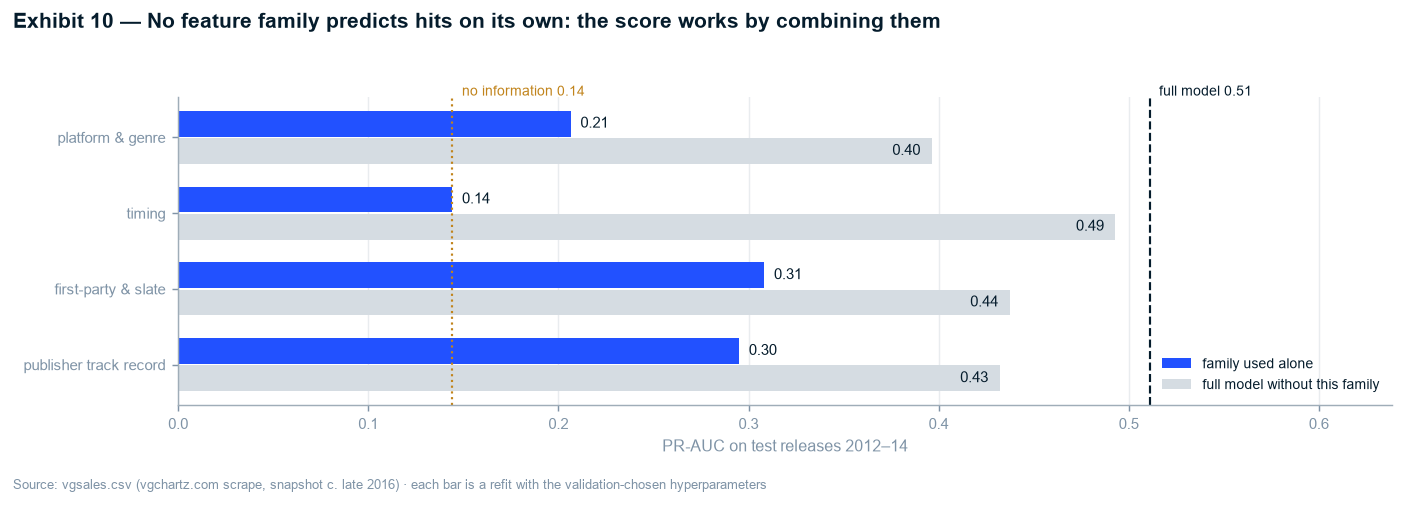

In [8]:
fig, ax = plt.subplots(figsize=(10.8, 3.4))
fams = list(FAMILIES)
alone = abl[abl["mode"] == "alone"].set_index("family").loc[fams, "PR-AUC"]
without = abl[abl["mode"] == "without"].set_index("family").loc[fams, "PR-AUC"]
yy = np.arange(len(fams))[::-1]
ax.barh(yy + 0.18, alone, height=0.34, color=BLUE, label="family used alone")
ax.barh(yy - 0.18, without, height=0.34, color=LIGHT, label="full model without this family")
for yi, a_, w_ in zip(yy, alone, without):
    ax.text(a_ + 0.005, yi + 0.18, f"{a_:.2f}", va="center", fontsize=8.5, color=NAVY)
    ax.text(w_ - 0.006, yi - 0.18, f"{w_:.2f}", va="center", ha="right", fontsize=8.5, color=NAVY)
ax.axvline(full, color=NAVY, lw=1.2, ls="--")
ax.text(full + 0.005, len(fams) - 0.45, f"full model {full:.2f}", fontsize=8, color=NAVY)
ax.axvline(BASE, color=AMBER, lw=1.2, ls=":")
ax.text(BASE + 0.005, len(fams) - 0.45, f"no information {BASE:.2f}", fontsize=8, color=AMBER)
ax.set_yticks(yy, fams)
ax.set_xlim(0, full * 1.25)
ax.set_xlabel("PR-AUC on test releases 2012–14")
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.legend(loc="lower right", fontsize=8)
suptitle(fig, "Exhibit 10 — No feature family predicts hits on its own: the score works by combining them")
finish(fig, "each bar is a refit with the validation-chosen hyperparameters")
plt.tight_layout()
save(fig, "ex10_ablation.png")
plt.show()

**So What:** the planned headline — "publisher track record carries the score" — did not survive the
ablation. Every family alone reaches at most 0.31 PR-AUC; together they reach 0.51. Platform & genre
are the weakest family alone (0.21) and yet the costliest to remove (−0.12), because they are
*context*: a publisher's track record means something different on a fading handheld than on a new
home console. Permutation importance agrees — the publisher's prior average sales, the platform, the
genre and the number of platforms launched at once are the top four, with nothing dominant.

This refines `04` §4.3 rather than contradicting it: *descriptively* publisher identity explains the
most variance, but *forward-looking* — where only past track record is available and new publishers
appear — the signal is in the combination.

**Implication:** no single rule ("only greenlight publishers with a hit record", "only make shooters")
captures what the score captures. That is the case for a model over a heuristic — and also the reason
it must be refitted on current data before use: interactions are what drift first.

### 6.2 Does it work for the stakeholder — third-party releases?

The stakeholder publishes no first-party titles. A score that only re-discovers "Nintendo publishes on
Nintendo hardware" would be useless to them, so performance is re-measured on **third-party test
releases only**, against the third-party base rate. Per-manufacturer results are the product-level
analogue of a subgroup fairness check: does the score work across platform families, or only on one?

In [9]:
tp = (test.first_party == 0).to_numpy()
BASE_TP = y_test[tp].mean()
tp_rows = []
for name in ["Gradient-boosted model", "Logistic regression", "Publisher prior hit rate"]:
    p = PRED[name]
    tp_rows.append({"model": name, "PR-AUC": average_precision_score(y_test[tp], p[tp]),
                    "precision@10%": prec_at(y_test[tp], p[tp]), "ROC-AUC": roc_auc_score(y_test[tp], p[tp])})
tp_res = pd.DataFrame(tp_rows).set_index("model")
tp_res["lift@10%"] = tp_res["precision@10%"] / BASE_TP
print(f"THIRD-PARTY test releases: {tp.sum():,} · base rate {BASE_TP:.3f}\n")
print(tp_res.round(3).to_string())

sub = []
for m_, g in test.assign(p=p_hgb).groupby("manufacturer"):
    if g.is_hit.nunique() < 2 or len(g) < 60:
        continue
    sub.append({"manufacturer": m_, "releases": len(g), "base rate": g.is_hit.mean(),
                "PR-AUC": average_precision_score(g.is_hit, g.p), "ROC-AUC": roc_auc_score(g.is_hit, g.p)})
sub = pd.DataFrame(sub).set_index("manufacturer")
sub["PR-AUC / base"] = sub["PR-AUC"] / sub["base rate"]
print()
print(sub.round(3).to_string())

THIRD-PARTY test releases: 1,544 · base rate 0.117

                          PR-AUC  precision@10%  ROC-AUC  lift@10%
model                                                             
Gradient-boosted model     0.466          0.461    0.839     3.955
Logistic regression        0.442          0.461    0.850     3.955
Publisher prior hit rate   0.271          0.325    0.779     2.785

              releases  base rate  PR-AUC  ROC-AUC  PR-AUC / base
manufacturer                                                     
Microsoft          317      0.246   0.555    0.769          2.255
Nintendo           438      0.121   0.558    0.880          4.608
PC                 144      0.069   0.603    0.803          8.689
Sony               799      0.130   0.474    0.854          3.639


**So What:** the score holds up where the stakeholder lives. On the 1,544 third-party test releases
(base rate 11.7%) its top decile hits 46% — the same 4.0× lift as on the full test set — while the
publisher-track-record heuristic manages 32%. Across platform families PR-AUC is 2.3–8.7× each
family's own base rate; the score is not a Nintendo detector.

### 6.3 Calibration — can the score be read as a probability?

In [10]:
frac, mean_p = calibration_curve(y_test, p_hgb, n_bins=10, strategy="quantile")
brier = brier_score_loss(y_test, p_hgb)
brier_base = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
print(f"Brier score {brier:.4f} vs {brier_base:.4f} for a constant train-rate forecast "
      f"(skill {1 - brier / brier_base:.1%})")
print(pd.DataFrame({"mean predicted": mean_p, "observed hit rate": frac}).round(3).to_string(index=False))
print(f"\nmean predicted {p_hgb.mean():.3f} vs observed {BASE:.3f} on test")

Brier score 0.1020 vs 0.1238 for a constant train-rate forecast (skill 17.6%)
 mean predicted  observed hit rate
          0.000              0.006
          0.001              0.000
          0.002              0.030
          0.004              0.012
          0.011              0.081
          0.022              0.096
          0.044              0.183
          0.084              0.199
          0.162              0.265
          0.407              0.574

mean predicted 0.074 vs observed 0.144 on test


**Verdict:** the score *ranks* well and is *miscalibrated* — it predicts a 7.4% hit rate for a test
window that delivered 14.4%. That is drift, and it is the drift `03` §3.1 and `04` §4.5 already found:
the model learned from 2009–11 that hit rates were falling, then the casual DS/Wii tier vanished and
the hit rate per release jumped. **Use the score as a ranking, never as a probability.** A deployed
version would need recalibration on the most recent complete year.

### 6.4 From score to slate (prescriptive layer, rung 5 — stated with its assumptions)

The committee's real question is slate size. Under the simplifying assumption that releases hit
independently, the number of releases needed for a 90% chance of at least one hit is
`n = ln(0.1) / ln(1 − p)`, where *p* is the hit rate of the releases chosen. The model changes *p*
only for the projects it ranks highly — and ranking requires candidates to rank, so this is an upper
bound on what a score can do for a slate, not a promise.

In [11]:
def n_for(p, conf=0.90):
    return int(np.ceil(np.log(1 - conf) / np.log(1 - p)))


sl = pd.DataFrame({
    "hit rate of chosen releases": [BASE_TP, tp_res.loc["Publisher prior hit rate", "precision@10%"],
                                    tp_res.loc["Gradient-boosted model", "precision@10%"]],
}, index=["third-party, unscreened", "top decile by publisher track record", "top decile by model score"])
sl["releases for 90% chance of ≥ 1 hit"] = sl.iloc[:, 0].map(n_for)
sl["expected hits per 10 releases"] = sl.iloc[:, 0] * 10
print(sl.round(2).to_string())

                                      hit rate of chosen releases  releases for 90% chance of ≥ 1 hit  expected hits per 10 releases
third-party, unscreened                                      0.12                                  19                           1.17
top decile by publisher track record                         0.32                                   6                           3.25
top decile by model score                                    0.46                                   4                           4.61


**So What:** for a third-party publisher, an unscreened release hits about 12% of the time, so a slate
needs roughly 19 releases for a 90% chance of at least one hit. If the candidates were drawn from the
top decile of the score, four would do. The real gain lies between those bounds: the committee ranks
*its own* pipeline, which is shorter and already filtered.

**Implication:** the defensible use is negative screening plus portfolio sizing — drop or re-scope
projects in the bottom half (2.6% hit rate), and size the remaining slate on the third-party base rate
rather than on the committee's conviction about any one title.

In [12]:
model_card = {
    "model": "HistGradientBoostingClassifier", "hyperparameters": BEST, "random_state": RANDOM_STATE,
    "target": "lifetime Global_Sales >= 1.0 M units (vgchartz estimate)",
    "unit": "game x platform release", "train": "release years <= 2011", "test": "2012-2014, titles unseen in train",
    "excluded": "2015-2016 (right-censored lifetime sales)", "features": FEATURES, "excluded_as_leakage": LEAKY,
    "test_metrics": {k: float(v) for k, v in res.loc["Gradient-boosted model", ["PR-AUC", "ROC-AUC", "precision@10%", "lift@10%"]].items()},
    "test_base_rate": float(BASE),
    "limitations": ["data ends 2016; physical retail only; no digital/mobile",
                    "vgchartz estimates, not audited sell-through",
                    "association only - a high score is not a reason a game will sell",
                    "publisher track record cannot score a publisher's first-ever release"],
    "monitoring": "not deployed; if adopted, refit annually on a current source and track platform-mix drift (PSI) and top-decile precision against realised sales",
}
(MODELS / "model_card.json").write_text(json.dumps(model_card, indent=1))
res.to_csv(REPORTS / "_model_results.csv")
abl.to_csv(REPORTS / "_ablation.csv", index=False)

g_ = res.loc["Gradient-boosted model"]
kf_update(
    model_test_n=len(test), model_test_base=BASE, model_test_removed_seen=n_test_before - len(test),
    model_train_n=len(train), model_best_params=json.dumps(BEST),
    hgb_pr_auc=g_["PR-AUC"], hgb_pr_auc_ci=[g_["PR-AUC lo"], g_["PR-AUC hi"]], hgb_roc_auc=g_["ROC-AUC"],
    hgb_prec10=g_["precision@10%"], hgb_prec10_ci=[g_["prec@10% lo"], g_["prec@10% hi"]],
    hgb_lift10=g_["lift@10%"], hgb_recall10=g_["recall@10%"],
    lr_pr_auc=res.loc["Logistic regression", "PR-AUC"], lr_prec10=res.loc["Logistic regression", "precision@10%"],
    pub_pr_auc=res.loc["Publisher prior hit rate", "PR-AUC"], pub_prec10=res.loc["Publisher prior hit rate", "precision@10%"],
    fp_flag_pr_auc=res.loc["First-party flag", "PR-AUC"],
    decile_top=by_dec.loc[1], decile_bottom=by_dec.loc[10], bottom_half_hit=bottom_half,
    abl_alone=abl[abl["mode"] == "alone"].set_index("family")["PR-AUC"].round(4).to_dict(),
    abl_without=abl[abl["mode"] == "without"].set_index("family")["PR-AUC"].round(4).to_dict(),
    tp_base=BASE_TP, tp_n=int(tp.sum()), tp_hgb_pr_auc=tp_res.loc["Gradient-boosted model", "PR-AUC"],
    tp_hgb_prec10=tp_res.loc["Gradient-boosted model", "precision@10%"],
    tp_hgb_lift10=tp_res.loc["Gradient-boosted model", "lift@10%"],
    tp_pub_prec10=tp_res.loc["Publisher prior hit rate", "precision@10%"],
    brier=brier, brier_skill=1 - brier / brier_base,
    hgb_mean_pred=float(p_hgb.mean()),
    slate_n_unscreened=int(sl.iloc[0, 1]), slate_n_pub=int(sl.iloc[1, 1]), slate_n_model=int(sl.iloc[2, 1]),
)

  _key_figures.json <- model_test_n, model_test_base, model_test_removed_seen, model_train_n, model_best_params, hgb_pr_auc, hgb_pr_auc_ci, hgb_roc_auc, hgb_prec10, hgb_prec10_ci, hgb_lift10, hgb_recall10, lr_pr_auc, lr_prec10, pub_pr_auc, pub_prec10, fp_flag_pr_auc, decile_top, decile_bottom, bottom_half_hit, abl_alone, abl_without, tp_base, tp_n, tp_hgb_pr_auc, tp_hgb_prec10, tp_hgb_lift10, tp_pub_prec10, brier, brier_skill, hgb_mean_pred, slate_n_unscreened, slate_n_pub, slate_n_model  (186 figures total)


## Stage 4 / 5 / 6 — Gate Checklists

**Stage 4 (features)**
- [x] Every feature is knowable at greenlight; the one outcome-derived family (publisher history) is
      time-fenced to strictly earlier years and the fence is asserted
- [x] Leakage reviewed: regional sales, `Rank`, `Global_Sales`, lifetime platform count and title
      aggregates excluded (the last two are leaks the data review did not list)
- [x] Importance assessed two ways (ablation refits + permutation importance on test)
- [x] Reproducible: features built in one cell from `vg_rows.parquet`, no manual steps

**Stage 6 (evaluation)**
- [x] Evaluated once on a held-out, later, title-disjoint test window; tuning used a separate validation window
- [x] Multiple metrics (PR-AUC, ROC-AUC, precision/recall@10%, Brier) with title-cluster bootstrap CIs
- [x] Compared against three baselines, including the committee's existing heuristics
- [x] Business impact quantified (decile hit rates, slate-size arithmetic with its assumptions stated)
- [x] Limitations documented in the model card (`models/model_card.json`)
- [x] Seeds fixed; hyperparameter grid recorded

**Cross-cutting**
- [x] Subgroup check: performance re-measured on third-party releases (the stakeholder's case) and per platform family
- [x] Monitoring plan stated in the model card — the model is *not* recommended for deployment on this data (see `06`)